<a href="https://colab.research.google.com/github/sungwon3615-cloud/Linear_Algebra/blob/main/ex02_transform_tiefighter_%EB%B0%B0%ED%8F%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [ ]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [ ]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [ ]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

# 점 p를 x를 sx만큼, y를 sy만큼 스케일을 변환시킨 점 q를 구할 것
def scale(p, sx, sy):
  # 1. 동차좌표계 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 크기 변환 행렬 생성
  m = np.array([[sx, 0.0, 0.0],[0.0, sy, 0.0],[0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

def rotate(p, theta):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 회전변환 행렬 생성
  m = np.array([[np.cos(theta), - np.sin(theta), 0.0], [np.sin(theta), np.cos(theta), 0.0],[0.0, 0.0, 1.0]])

  # 3. 행렬과 백터의 곱
  q = np.dop(m, hp)

  #4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

def shear_x(p, sx):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, sx, 0.0],
                  [0.0, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])


def shear_y(p, sy):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, 0.0, 0.0],
                  [sy, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

def reflect_x(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, 0.0, 0.0],
                  [0.0, -1.0, 0.0],
                  [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [70]:
# 1. 중앙 조종석 그리기
def draw_cockpit(ax, p1, p2, p3, p4):
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    s = 5
    q1 = scale(q1, s, s)
    q2 = scale(q2, s, s)
    q3 = scale(q3, s, s)
    q4 = scale(q4, s, s)

    q1 = rotate(q1, 3.14/4.0)
    q2 = rotate(q2, 3.14/4.0)
    q3 = rotate(q3, 3.14/4.0)
    q4 = rotate(q4, 3.14/4.0)

    draw_rectangle(ax, q1, q2, q3, q4)

# 2. 왼쪽 날개축
def draw_left_arm(ax, p1, p2, p3, p4):
    u1 = np.array([-750, 0])
    u2 = np.array([-150, 40])
    u3 = np.array([-150, 140])
    u4 = np.array([-750, 50])
    draw_rectangle(ax, u1, u2, u3, u4)

    l1 = np.array([-750, -50])
    l2 = np.array([-150, -140])
    l3 = np.array([-150, -40])
    l4 = np.array([-750, 0])
    draw_rectangle(ax, l1, l2, l3, l4)

# 3. 왼쪽 날개
def draw_left_wing(ax, p1, p2, p3, p4):
    q1 = np.array([-850, -500])
    q2 = np.array([-750, -300])
    q3 = np.array([-750, 300])
    q4 = np.array([-850, 500])
    draw_rectangle(ax, q1, q2, q3, q4)

# 4. 오른쪽 날개축
def draw_right_arm(ax, p1, p2, p3, p4):
    u1 = np.array([750, 50])
    u2 = np.array([150, 140])
    u3 = np.array([150, 40])
    u4 = np.array([750, 0])
    draw_rectangle(ax, u1, u2, u3, u4)

    l1 = np.array([750, 0])
    l2 = np.array([150, -40])
    l3 = np.array([150, -140])
    l4 = np.array([750, -50])
    draw_rectangle(ax, l1, l2, l3, l4)

# 5. 오른쪽 날개
def draw_right_wing(ax, p1, p2, p3, p4):
    q1 = np.array([750, -300])
    q2 = np.array([850, -500])
    q3 = np.array([850, 500])
    q4 = np.array([750, 300])
    draw_rectangle(ax, q1, q2, q3, q4)
# 전체 그리기
def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    draw_cockpit(ax, p1, p2, p3, p4)
    draw_left_arm(ax, p1, p2, p3, p4)
    draw_left_wing(ax, p1, p2, p3, p4)
    draw_right_arm(ax, p1, p2, p3, p4)
    draw_right_wing(ax, p1, p2, p3, p4)

### 3. main

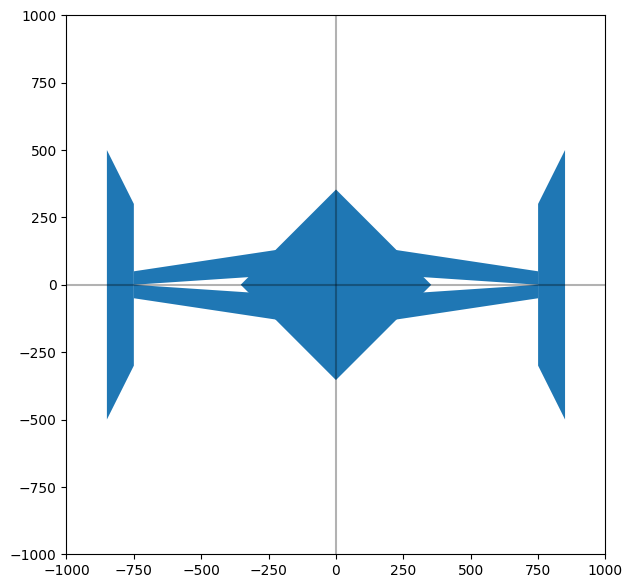

In [71]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()